# Lab #7
Name: Maan Abdullah Alghamdi  
ID: 2240001433  
Course: ARTI 403 - Image Processing
## Part A - Laplacian Filter
I completed this notebook using the supplied images. I run the cells in order
from a fresh kernel. All image paths are relative to the notebook folder.

## Setup

In [1]:
from pathlib import Path
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def load_gray(name):
    path = Path(name)
    if not path.is_file():
        raise FileNotFoundError(f"Keep {name} beside this notebook: {Path.cwd()}")
    image = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not decode {path}")
    return image

def to_uint8(values):
    return np.rint(np.clip(values, 0, 255)).astype(np.uint8)

def show_images(images, titles, cols=2):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(10, 3.5 * rows), squeeze=False)
    for ax, image, label in zip(axes.flat, images, titles):
        ax.imshow(image, cmap='gray', vmin=0, vmax=255)
        ax.set_title(label)
        ax.axis('off')
    for ax in axes.flat[len(images):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()
    plt.close(fig)

print(f"Python {sys.version.split()[0]} | OpenCV {cv2.__version__}")
print(f"NumPy {np.__version__}")

Python 3.12.10 | OpenCV 5.0.0
NumPy 2.5.2


## A1. Manual Laplacian sharpening
I use the four-neighbour kernel with a negative centre. Its response L contains
both positive and negative values, so I keep it in floating point. I sharpen with
g = clip(f - L, 0, 255). The absolute response is only an edge visualization;
adding it to uint8 pixels would not implement this signed sharpening formula.

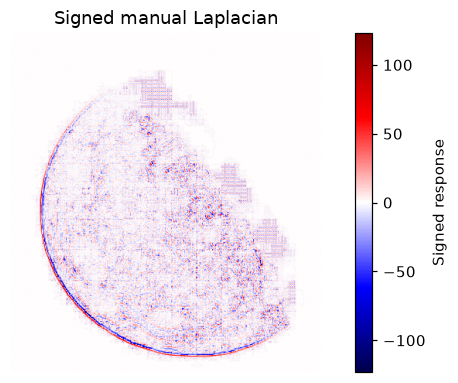

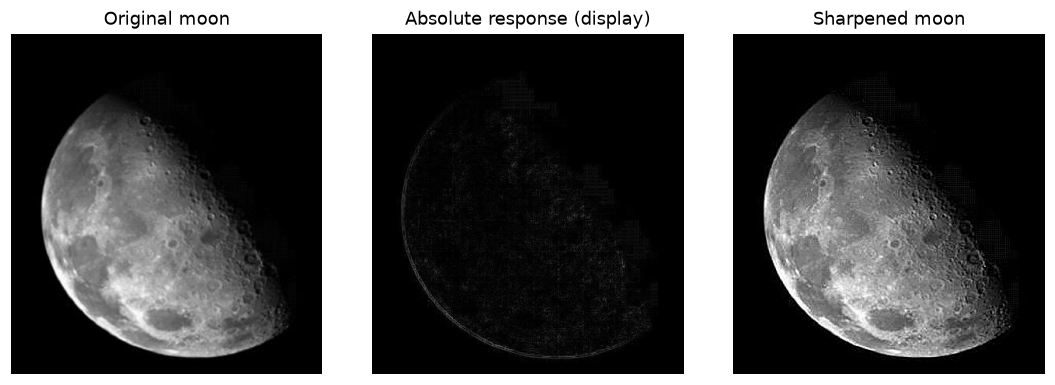

Signed range: -123.0 to 110.0


In [2]:
img = load_gray('moon.jpg')
manual_kernel = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float64)
laplacian_manual = cv2.filter2D(
    img, cv2.CV_64F, manual_kernel, borderType=cv2.BORDER_REFLECT_101)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)
sharpened_manual = to_uint8(img.astype(np.float64) - laplacian_manual)

# A zero-centred scale makes the sign of the response visible.
fig, ax = plt.subplots(figsize=(8, 4))
limit = max(float(np.abs(laplacian_manual).max()), 1.0)
plot = ax.imshow(laplacian_manual, cmap='seismic', vmin=-limit, vmax=limit)
ax.set_title('Signed manual Laplacian')
ax.axis('off')
fig.colorbar(plot, ax=ax, label='Signed response')
plt.show()
plt.close(fig)
show_images([img, laplacian_abs, sharpened_manual],
            ['Original moon', 'Absolute response (display)', 'Sharpened moon'], 3)
print('Signed range:', laplacian_manual.min(), 'to', laplacian_manual.max())

## A2. OpenCV Laplacian with optional smoothing
I first verify that cv2.Laplacian with ksize=1 agrees with my manual kernel.
Then I blur the image with a 3 x 3 Gaussian before calculating the response.
I subtract this smoothed response from the original to reduce sensitivity to
small noisy details while sharpening. Smoothing changes the result deliberately.

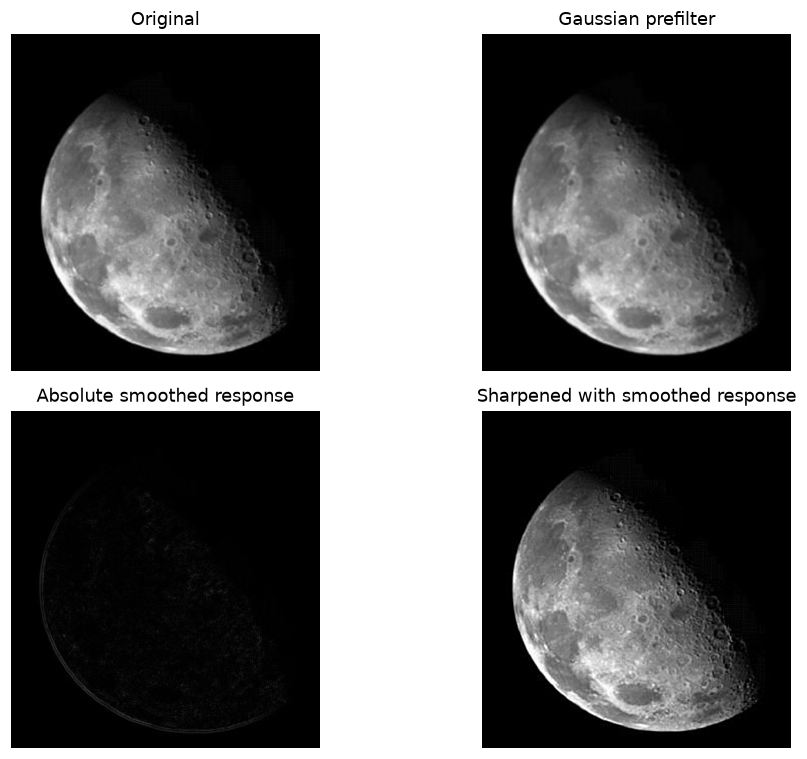

Manual/OpenCV maximum difference: 0.0


In [3]:
laplacian_builtin = cv2.Laplacian(
    img, cv2.CV_64F, ksize=1, borderType=cv2.BORDER_REFLECT_101)
blurred = cv2.GaussianBlur(img, (3, 3), 0, borderType=cv2.BORDER_REFLECT_101)
laplacian_smoothed = cv2.Laplacian(
    blurred, cv2.CV_64F, ksize=1, borderType=cv2.BORDER_REFLECT_101)
sharpened_smoothed = to_uint8(img.astype(np.float64) - laplacian_smoothed)
show_images([img, blurred, cv2.convertScaleAbs(laplacian_smoothed),
             sharpened_smoothed],
            ['Original', 'Gaussian prefilter', 'Absolute smoothed response',
             'Sharpened with smoothed response'])
print('Manual/OpenCV maximum difference:',
      np.max(np.abs(laplacian_manual - laplacian_builtin)))

## A3. Checks and observations
I expect the two unsmoothed implementations to match. I clip before conversion
so bright and dark pixels cannot wrap around. The raw Laplacian emphasizes
fine edges; the Gaussian-prefiltered version produces a gentler change. I do
not claim a restoration accuracy score because no ideal sharp reference exists.

In [4]:
assert np.allclose(laplacian_manual, laplacian_builtin)
assert manual_kernel.sum() == 0
assert np.all(cv2.filter2D(np.full((9, 9), 80, np.uint8),
                         cv2.CV_64F, manual_kernel) == 0)
assert np.array_equal(to_uint8(np.array([-20., 280.])), [0, 255])
for result in [sharpened_manual, sharpened_smoothed]:
    assert result.shape == img.shape and result.dtype == np.uint8
print('Part A: all numerical and image checks passed.')

Part A: all numerical and image checks passed.
